# Logistic Regression — Predicting Professor Research Area & Impact

This notebook builds logistic regression models for:
1. **Binary Classification** — Is this professor high-impact? (top venue papers >= median)
2. **Multiclass Classification** — Which research area does the professor belong to?

**Workflow:**
- Data loading & preprocessing
- Feature engineering
- Binary classification (High Impact)
- Multiclass classification (Research Area)
- Model evaluation & comparison

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, auc,
    ConfusionMatrixDisplay, RocCurveDisplay
)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

print('Libraries loaded successfully.')

Libraries loaded successfully.


## 1. Data Loading & Preprocessing

In [2]:
df = pd.read_csv('../dataset/professors.csv')
print(f'Shape: {df.shape}')
df.head()

Shape: (317, 26)


,Professor,University,Rank,rank_place,Research area,OpenAlex_Author_ID,Author_Status,Matched_Institution,Venues,Number_of_Top_Venue_Papers,...,AAAI,IJCAI,CVPR,ICCV,ECCV,ACL,EMNLP,NAACL,profile_url,Email
0,Xiaowei Jia,University of Pittsburgh,r1,67,Other,A5001445783,MATCHED,University of Pittsburgh,AAAI,10,...,12,0,0,0,0,0,0,0,NaN,NaN
1,Vincent Conitzer,Carnegie Mellon University,r1,24,Artificial Intelligence,A5050903632,MATCHED,Carnegie Mellon University,AAAI,9,...,22,0,0,0,0,0,0,0,https://csd.cmu.edu/people/faculty/vincent-con...,c@cmu.edu
2,Alan Fern,Oregon State University,r1,142,Artificial Intelligence,A5030052689,MATCHED,Oregon State University,AAAI,8,...,12,0,0,0,0,0,0,0,NaN,NaN
3,Kuldeep S. Meel,Georgia Institute of Technology (Georgia Tech),r1,33,Artificial Intelligence,A5041528950,MATCHED,Georgia Institute of Technology,AAAI,8,...,16,0,0,0,0,0,0,0,https://scs.gatech.edu/people/kuldeep-s-meel,NaN
4,Tianlong Chen,University of North Carolina at Chapel Hill,r1,22,Machine Learning,A5103073431,MATCHED,University of North Carolina at Chapel Hill,AAAI,8,...,8,0,3,0,0,0,0,0,NaN,NaN


In [3]:
# Drop non-predictive columns
df.drop(columns=['OpenAlex_Author_ID', 'Author_Status', 'Matched_Institution',
                  'profile_url', 'Email', 'Professor'], inplace=True)

# Replace missing with NaN
df.replace('missing', np.nan, inplace=True)

# Convert numeric columns
for col in ['h_index', 'total_citations']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Parse Years
df['Num_Years'] = df['Years'].apply(lambda x: len(str(x).split(';')) if pd.notna(x) else 1)
df.drop(columns=['Years'], inplace=True)

# Fill missing
for c in df.select_dtypes(include=[np.number]).columns:
    df[c] = pd.to_numeric(df[c], errors='coerce').fillna(0)
for c in df.select_dtypes(include='object').columns:
    df[c].fillna('missing', inplace=True)

print(f'Shape after cleaning: {df.shape}')
print(f'Remaining missing: {df.isnull().sum().sum()}')
df.head()

Shape after cleaning: (317, 20)
Remaining missing: 0


,University,Rank,rank_place,Research area,Venues,Number_of_Top_Venue_Papers,h_index,total_citations,NeurIPS,ICML,ICLR,AAAI,IJCAI,CVPR,ICCV,ECCV,ACL,EMNLP,NAACL,Num_Years
0,University of Pittsburgh,r1,67,Other,AAAI,10,29.0,4753.0,0,0,0,12,0,0,0,0,0,0,0,3
1,Carnegie Mellon University,r1,24,Artificial Intelligence,AAAI,9,54.0,10549.0,2,2,0,22,0,0,0,0,0,0,0,3
2,Oregon State University,r1,142,Artificial Intelligence,AAAI,8,40.0,5678.0,0,0,1,12,0,0,0,0,0,0,0,3
3,Georgia Institute of Technology (Georgia Tech),r1,33,Artificial Intelligence,AAAI,8,26.0,2332.0,1,0,0,16,0,0,0,0,0,0,0,3
4,University of North Carolina at Chapel Hill,r1,22,Machine Learning,AAAI,8,31.0,4324.0,2,0,0,8,0,3,0,0,0,0,0,3


In [4]:
# Feature engineering
venue_cols = ['NeurIPS', 'ICML', 'ICLR', 'AAAI', 'IJCAI', 'CVPR', 'ICCV', 'ECCV', 'ACL', 'EMNLP', 'NAACL']

df['Total_Venue_Papers'] = df[venue_cols].sum(axis=1)
df['Num_Distinct_Venues'] = (df[venue_cols] > 0).sum(axis=1)
df['Venue_Diversity_Ratio'] = df['Num_Distinct_Venues'] / len(venue_cols)
df['Citations_Per_Year'] = df['total_citations'] / df['Num_Years'].replace(0, 1)
df['H_Index_Per_Year'] = df['h_index'] / df['Num_Years'].replace(0, 1)
df['Top_Venue_Papers_Per_Year'] = df['Number_of_Top_Venue_Papers'] / df['Num_Years'].replace(0, 1)
df['CV_Total'] = df[['CVPR', 'ICCV', 'ECCV']].sum(axis=1)
df['NLP_Total'] = df[['ACL', 'EMNLP', 'NAACL']].sum(axis=1)
df['ML_Systems_Total'] = df[['NeurIPS', 'ICML', 'ICLR']].sum(axis=1)
df['AAAI_Dominance'] = df['AAAI'] / df['Total_Venue_Papers'].replace(0, 1)
ai_areas = ['Artificial Intelligence', 'Machine Learning', 'Deep Learning', 'Reinforcement Learning']
df['Is_AI_Researcher'] = df['Research area'].isin(ai_areas).astype(int)

print(f'Features after engineering: {df.shape[1]}')
df.head()

Features after engineering: 31


,University,Rank,rank_place,Research area,Venues,Number_of_Top_Venue_Papers,h_index,total_citations,NeurIPS,ICML,...,Num_Distinct_Venues,Venue_Diversity_Ratio,Citations_Per_Year,H_Index_Per_Year,Top_Venue_Papers_Per_Year,CV_Total,NLP_Total,ML_Systems_Total,AAAI_Dominance,Is_AI_Researcher
0,University of Pittsburgh,r1,67,Other,AAAI,10,29.0,4753.0,0,0,...,1,0.090909,1584.333333,9.666667,3.333333,0,0,0,1.000000,0
1,Carnegie Mellon University,r1,24,Artificial Intelligence,AAAI,9,54.0,10549.0,2,2,...,3,0.272727,3516.333333,18.000000,3.000000,0,0,4,0.846154,1
2,Oregon State University,r1,142,Artificial Intelligence,AAAI,8,40.0,5678.0,0,0,...,2,0.181818,1892.666667,13.333333,2.666667,0,0,1,0.923077,1
3,Georgia Institute of Technology (Georgia Tech),r1,33,Artificial Intelligence,AAAI,8,26.0,2332.0,1,0,...,2,0.181818,777.333333,8.666667,2.666667,0,0,1,0.941176,1
4,University of North Carolina at Chapel Hill,r1,22,Machine Learning,AAAI,8,31.0,4324.0,2,0,...,3,0.272727,1441.333333,10.333333,2.666667,3,0,2,0.615385,1


## 2. Binary Classification — High Impact Professor

Target: `Is_High_Impact` = 1 if `Number_of_Top_Venue_Papers >= median`, else 0

Threshold (median citations): 4503.0

Target distribution:
Is_High_Impact
1    159
0    158
Name: count, dtype: int64


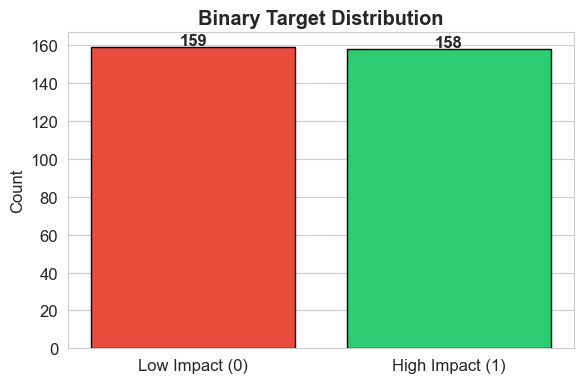

In [5]:
# Create binary target based on citations (more balanced)
median_citations = df['total_citations'].median()
df['Is_High_Impact'] = (df['total_citations'] >= median_citations).astype(int)

print(f'Threshold (median citations): {median_citations}')
print(f'\nTarget distribution:')
print(df['Is_High_Impact'].value_counts())

fig, ax = plt.subplots(figsize=(6, 4))
counts = df['Is_High_Impact'].value_counts()
bars = ax.bar(['Low Impact (0)', 'High Impact (1)'], counts.values,
              color=['#e74c3c', '#2ecc71'], edgecolor='black')
ax.set_title('Binary Target Distribution', fontweight='bold')
ax.set_ylabel('Count')
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 1, str(val), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [6]:
# Features for binary classification
drop_binary = ['Is_High_Impact', 'Number_of_Top_Venue_Papers', 'Citations_Per_Year']
feature_cols = [c for c in df.columns if c not in drop_binary]

X_bin = df[feature_cols].copy()
y_bin = df['Is_High_Impact'].copy()

cat_features = X_bin.select_dtypes(include='object').columns.tolist()
num_features = X_bin.select_dtypes(include=[np.number]).columns.tolist()

print(f'Features: {len(feature_cols)} (cat: {len(cat_features)}, num: {len(num_features)})')
print(f'Target: Is_High_Impact (n={len(y_bin)})')
print(f'Class balance: {y_bin.value_counts().to_dict()}')

Features: 29 (cat: 4, num: 25)
Target: Is_High_Impact (n=317)
Class balance: {1: 159, 0: 158}


In [7]:
# Train/test split
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X_bin, y_bin, test_size=0.2, random_state=42, stratify=y_bin
)
print(f'Train: {Xb_train.shape[0]} | Test: {Xb_test.shape[0]}')
print(f'Train target dist:\n{yb_train.value_counts()}')
print(f'\nTest target dist:\n{yb_test.value_counts()}')

Train: 253 | Test: 64


Train target dist:
Is_High_Impact
1    127
0    126
Name: count, dtype: int64

Test target dist:
Is_High_Impact
1    32
0    32
Name: count, dtype: int64


In [8]:
# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ],
    remainder='drop'
)

In [9]:
# Binary logistic regression
bin_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])

bin_pipeline.fit(Xb_train, yb_train)

yb_pred = bin_pipeline.predict(Xb_test)
yb_pred_proba = bin_pipeline.predict_proba(Xb_test)[:, 1]

print('Binary model trained.')

Binary model trained.


In [10]:
# Evaluation metrics
print('='*55)
print('  BINARY CLASSIFICATION -- High Impact Prediction')
print('='*55)
print(f'  Accuracy:  {accuracy_score(yb_test, yb_pred):.4f}')
print(f'  Precision: {precision_score(yb_test, yb_pred):.4f}')
print(f'  Recall:    {recall_score(yb_test, yb_pred):.4f}')
print(f'  F1 Score:  {f1_score(yb_test, yb_pred):.4f}')
print('='*55)
print(f'\nClassification Report:\n')
print(classification_report(yb_test, yb_pred, target_names=['Low Impact', 'High Impact']))

  BINARY CLASSIFICATION -- High Impact Prediction
  Accuracy:  0.9219
  Precision: 0.9655
  Recall:    0.8750
  F1 Score:  0.9180

Classification Report:

              precision    recall  f1-score   support

  Low Impact       0.89      0.97      0.93        32
 High Impact       0.97      0.88      0.92        32

    accuracy                           0.92        64
   macro avg       0.93      0.92      0.92        64
weighted avg       0.93      0.92      0.92        64



In [11]:
# Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(bin_pipeline, X_bin, y_bin, cv=cv, scoring='f1')
print(f'5-Fold CV F1: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}')
print(f'Individual folds: {[f"{s:.4f}" for s in cv_scores]}')

5-Fold CV F1: 0.9167 +/- 0.0519
Individual folds: ['0.9333', '0.8438', '0.8710', '0.9846', '0.9508']


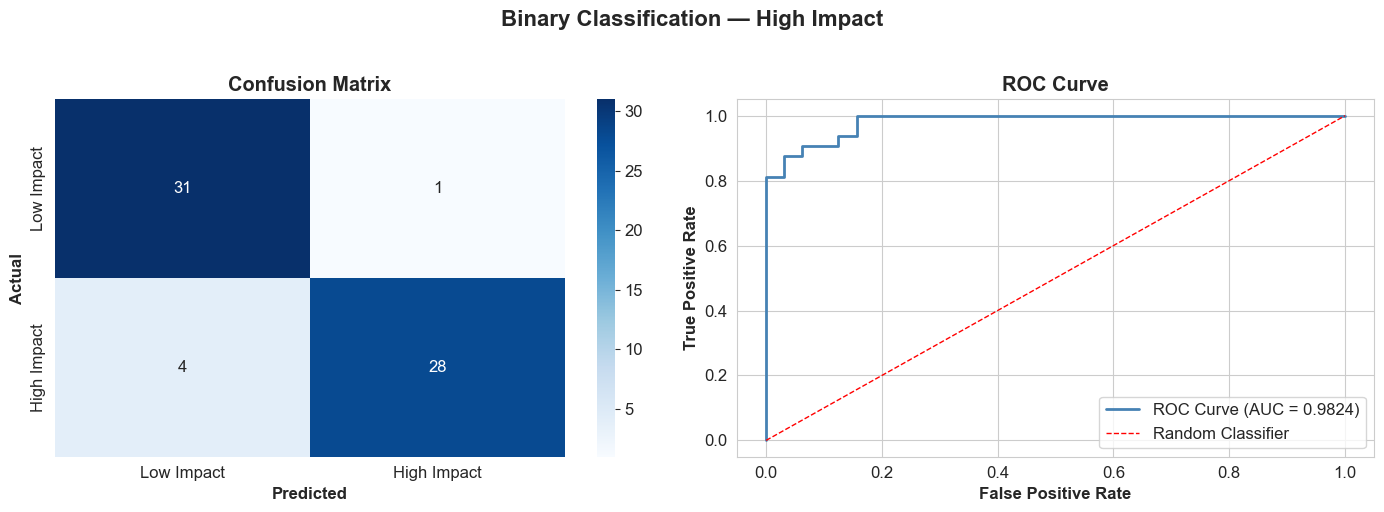

In [12]:
# Confusion matrix and ROC curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(yb_test, yb_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Low Impact', 'High Impact'],
            yticklabels=['Low Impact', 'High Impact'])
axes[0].set_xlabel('Predicted', fontweight='bold')
axes[0].set_ylabel('Actual', fontweight='bold')
axes[0].set_title('Confusion Matrix', fontweight='bold')

# ROC Curve
fpr, tpr, thresholds = roc_curve(yb_test, yb_pred_proba)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='steelblue', linewidth=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], 'r--', linewidth=1, label='Random Classifier')
axes[1].set_xlabel('False Positive Rate', fontweight='bold')
axes[1].set_ylabel('True Positive Rate', fontweight='bold')
axes[1].set_title('ROC Curve', fontweight='bold')
axes[1].legend(loc='lower right')

plt.suptitle('Binary Classification — High Impact', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

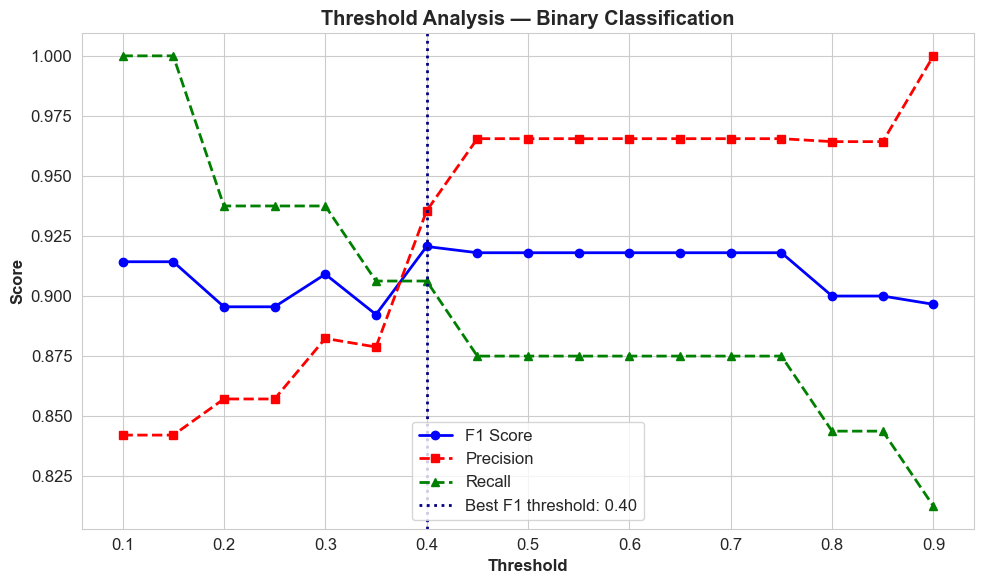

Best threshold: 0.40 (F1=0.9206)


In [13]:
# Threshold analysis
thresholds_range = np.arange(0.1, 0.95, 0.05)
f1_scores = []
prec_scores = []
rec_scores = []

for t in thresholds_range:
    yb_pred_t = (yb_pred_proba >= t).astype(int)
    f1_scores.append(f1_score(yb_test, yb_pred_t, zero_division=0))
    prec_scores.append(precision_score(yb_test, yb_pred_t, zero_division=0))
    rec_scores.append(recall_score(yb_test, yb_pred_t, zero_division=0))

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(thresholds_range, f1_scores, 'bo-', linewidth=2, markersize=6, label='F1 Score')
ax.plot(thresholds_range, prec_scores, 'rs--', linewidth=2, markersize=6, label='Precision')
ax.plot(thresholds_range, rec_scores, 'g^--', linewidth=2, markersize=6, label='Recall')
best_idx = np.argmax(f1_scores)
ax.axvline(thresholds_range[best_idx], color='navy', linestyle=':', linewidth=2,
           label=f'Best F1 threshold: {thresholds_range[best_idx]:.2f}')
ax.set_xlabel('Threshold', fontweight='bold')
ax.set_ylabel('Score', fontweight='bold')
ax.set_title('Threshold Analysis — Binary Classification', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Best threshold: {thresholds_range[best_idx]:.2f} (F1={f1_scores[best_idx]:.4f})')

## 3. Multiclass Classification — Research Area

Research Area Distribution:
Research area
Machine Learning               131
Other                           45
Artificial Intelligence         42
Computer Vision                 22
Cryptography & Security         18
Deep Learning                   17
NLP                             15
Reinforcement Learning          13
Natural Language Processing     10
Large Language Models            4
Name: count, dtype: int64


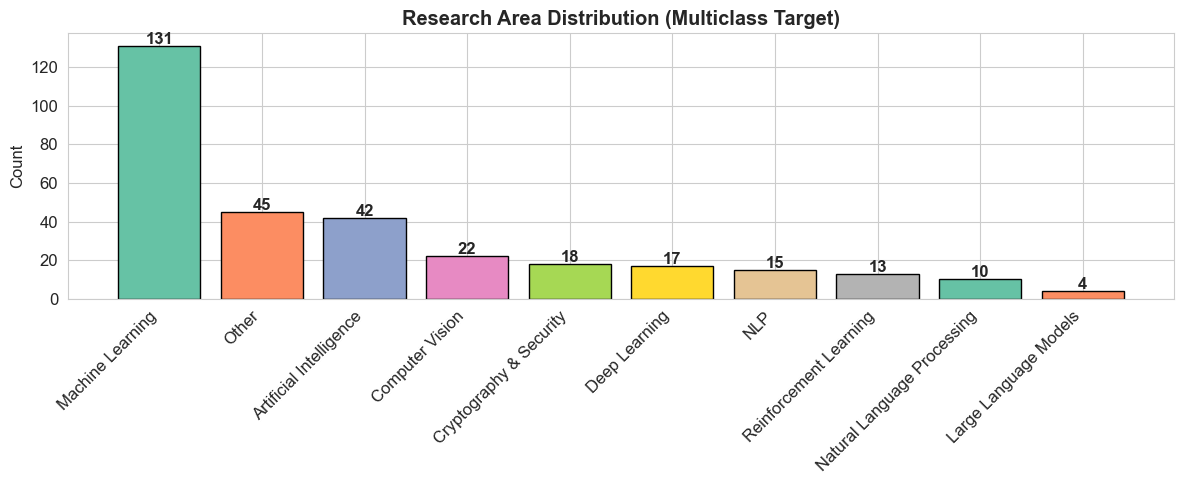

In [14]:
# Target distribution
ra_counts = df['Research area'].value_counts()
print('Research Area Distribution:')
print(ra_counts)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(range(len(ra_counts)), ra_counts.values,
              color=sns.color_palette('Set2', len(ra_counts)), edgecolor='black')
ax.set_xticks(range(len(ra_counts)))
ax.set_xticklabels(ra_counts.index, rotation=45, ha='right')
ax.set_title('Research Area Distribution (Multiclass Target)', fontweight='bold')
ax.set_ylabel('Count')
for bar, val in zip(bars, ra_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 1, str(val), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [15]:
# Encode target
le = LabelEncoder()
df['Research_Area_Enc'] = le.fit_transform(df['Research area'])
class_names = le.classes_
print(f'Classes: {list(class_names)}')

# Features — drop target-related columns
drop_multi = ['Research area', 'Research_Area_Enc', 'Is_High_Impact', 'Citations_Per_Year']
feature_cols_multi = [c for c in df.columns if c not in drop_multi]

X_mc = df[feature_cols_multi].copy()
y_mc = df['Research_Area_Enc'].copy()

cat_features_mc = X_mc.select_dtypes(include='object').columns.tolist()
num_features_mc = X_mc.select_dtypes(include=[np.number]).columns.tolist()

print(f'Features: {len(feature_cols_multi)} (cat: {len(cat_features_mc)}, num: {len(num_features_mc)})')

Classes: ['Artificial Intelligence', 'Computer Vision', 'Cryptography & Security', 'Deep Learning', 'Large Language Models', 'Machine Learning', 'NLP', 'Natural Language Processing', 'Other', 'Reinforcement Learning']
Features: 29 (cat: 3, num: 26)


In [16]:
# Train/test split
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X_mc, y_mc, test_size=0.2, random_state=42, stratify=y_mc
)
print(f'Train: {Xm_train.shape[0]} | Test: {Xm_test.shape[0]}')

Train: 253 | Test: 64


In [17]:
# Preprocessor for multiclass
preprocessor_mc = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features_mc),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features_mc)
    ],
    remainder='drop'
)

In [18]:
# Multinomial Logistic Regression
mc_pipeline = Pipeline([
    ('preprocessor', preprocessor_mc),
    ('classifier', LogisticRegression(
        solver='lbfgs', max_iter=2000,
        random_state=42, class_weight='balanced', C=1.0
    ))
])

mc_pipeline.fit(Xm_train, ym_train)

ym_pred = mc_pipeline.predict(Xm_test)
ym_pred_proba = mc_pipeline.predict_proba(Xm_test)

print('Multiclass model trained.')

Multiclass model trained.


In [19]:
# Evaluation
print('='*55)
print('  MULTICLASS — Research Area Prediction')
print('='*55)
print(f'  Accuracy (weighted):     {accuracy_score(ym_test, ym_pred):.4f}')
print(f'  Precision (weighted):    {precision_score(ym_test, ym_pred, average="weighted"):.4f}')
print(f'  Recall (weighted):       {recall_score(ym_test, ym_pred, average="weighted"):.4f}')
print(f'  F1 Score (weighted):     {f1_score(ym_test, ym_pred, average="weighted"):.4f}')
print(f'  F1 Score (macro):        {f1_score(ym_test, ym_pred, average="macro"):.4f}')
print('='*55)
print(f'\nClassification Report:\n')
print(classification_report(ym_test, ym_pred, target_names=class_names))

  MULTICLASS — Research Area Prediction
  Accuracy (weighted):     0.4375
  Precision (weighted):    0.5407
  Recall (weighted):       0.4375
  F1 Score (weighted):     0.4616
  F1 Score (macro):        0.3581

Classification Report:

                             precision    recall  f1-score   support

    Artificial Intelligence       0.33      0.22      0.27         9
            Computer Vision       0.67      0.50      0.57         4
    Cryptography & Security       0.33      0.25      0.29         4
              Deep Learning       0.14      0.67      0.24         3
      Large Language Models       0.00      0.00      0.00         1
           Machine Learning       0.75      0.46      0.57        26
                        NLP       0.50      0.33      0.40         3
Natural Language Processing       0.33      0.50      0.40         2
                      Other       0.55      0.67      0.60         9
     Reinforcement Learning       0.20      0.33      0.25         3

    

In [20]:
# Cross-validation
cv_mc = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_mc = cross_val_score(mc_pipeline, X_mc, y_mc, cv=cv_mc, scoring='f1_weighted')
print(f'5-Fold CV F1 (weighted): {cv_scores_mc.mean():.4f} +/- {cv_scores_mc.std():.4f}')
print(f'Individual folds: {[f"{s:.4f}" for s in cv_scores_mc]}')

5-Fold CV F1 (weighted): 0.4307 +/- 0.0316
Individual folds: ['0.3734', '0.4596', '0.4336', '0.4598', '0.4272']


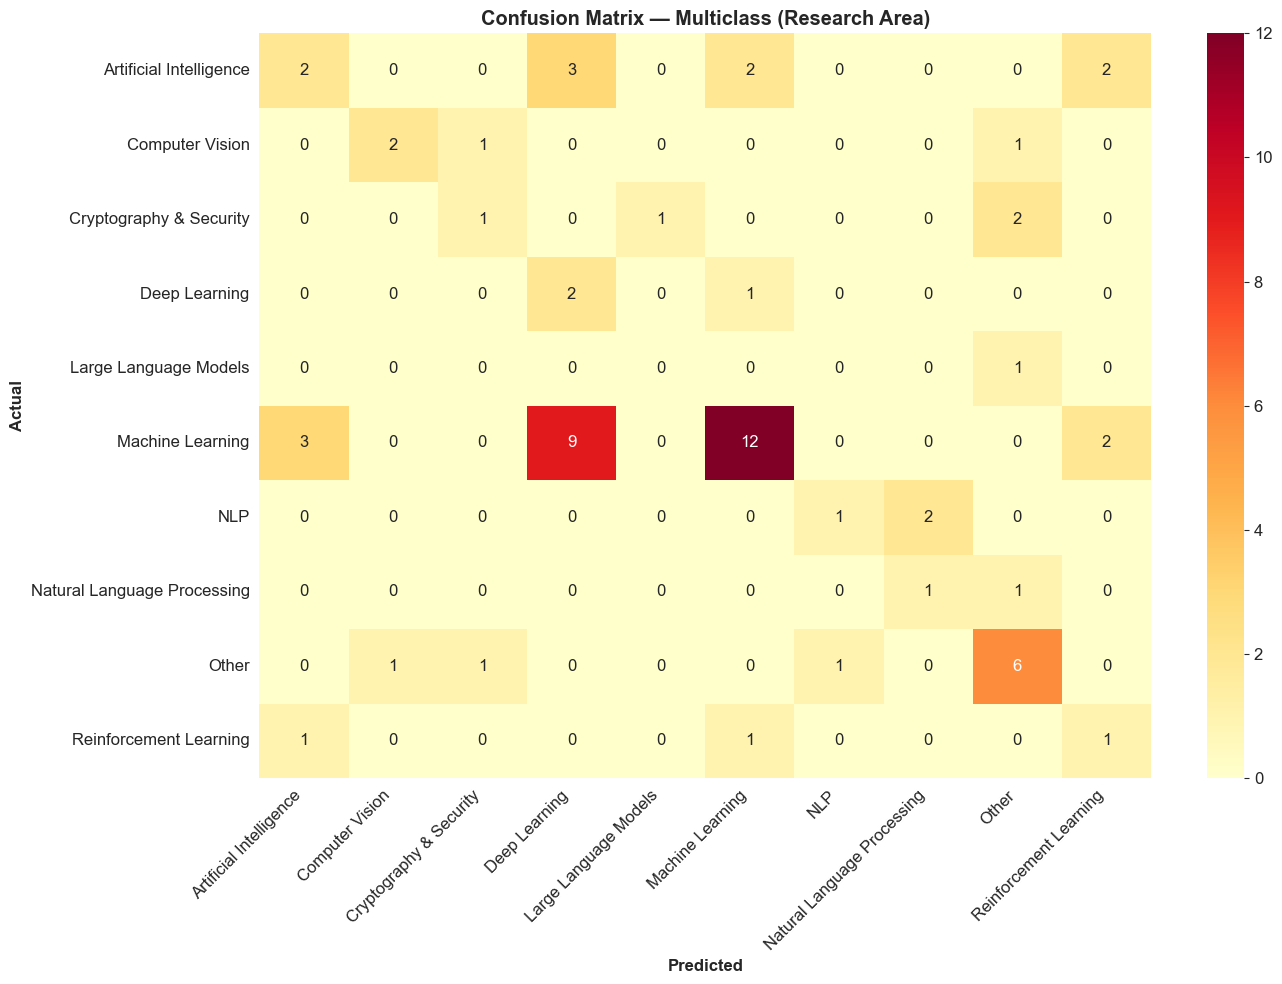

In [21]:
# Confusion Matrix
fig, ax = plt.subplots(figsize=(14, 10))
cm_mc = confusion_matrix(ym_test, ym_pred)
sns.heatmap(cm_mc, annot=True, fmt='d', cmap='YlOrRd', ax=ax,
            xticklabels=class_names, yticklabels=class_names)
ax.set_xlabel('Predicted', fontweight='bold')
ax.set_ylabel('Actual', fontweight='bold')
ax.set_title('Confusion Matrix — Multiclass (Research Area)', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

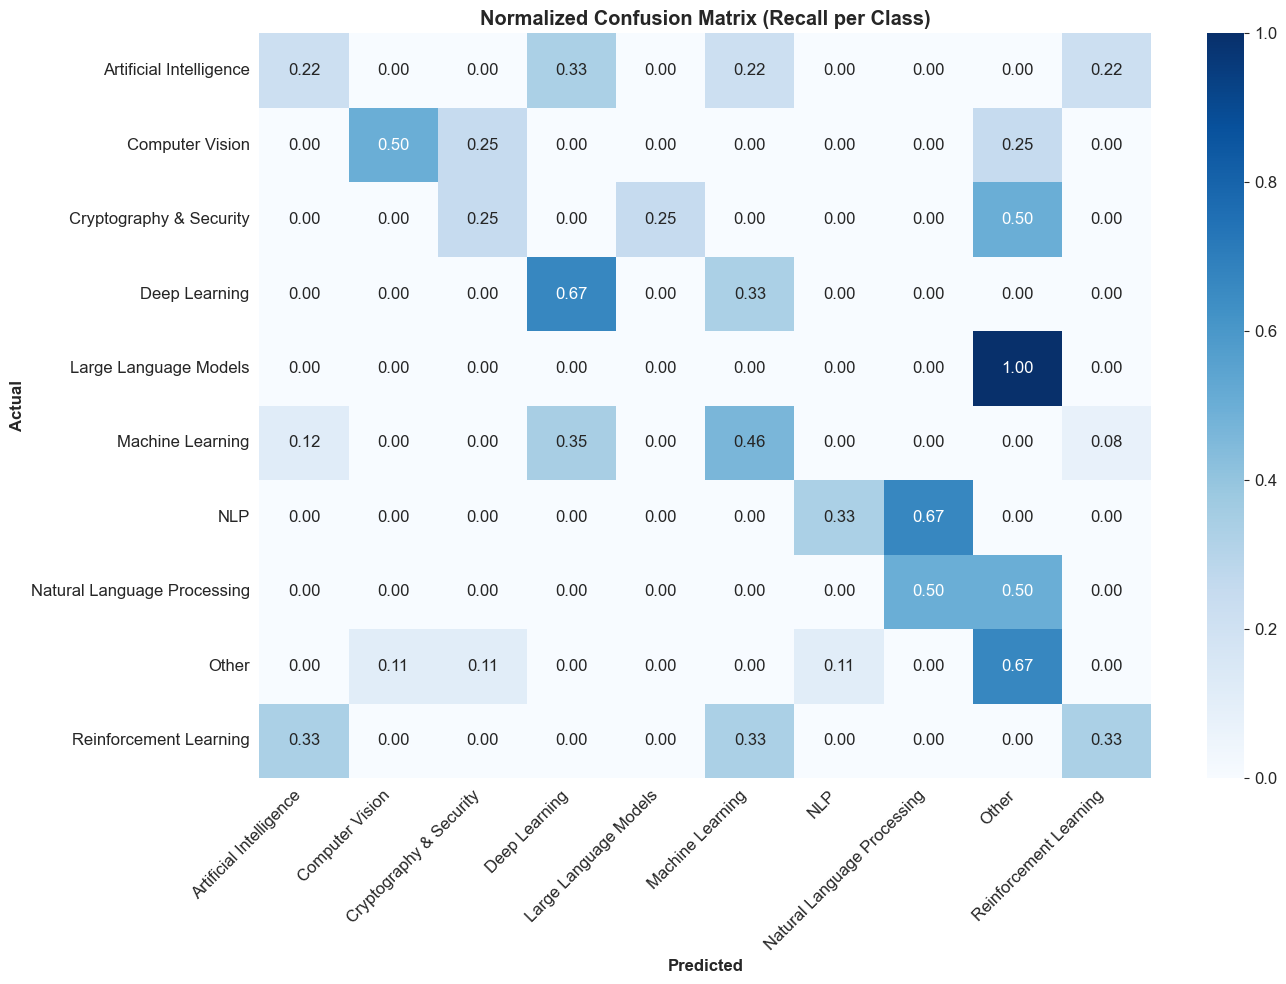

In [22]:
# Normalized confusion matrix
cm_norm = cm_mc.astype('float') / cm_mc.sum(axis=1)[:, np.newaxis]

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', ax=ax,
            xticklabels=class_names, yticklabels=class_names,
            vmin=0, vmax=1)
ax.set_xlabel('Predicted', fontweight='bold')
ax.set_ylabel('Actual', fontweight='bold')
ax.set_title('Normalized Confusion Matrix (Recall per Class)', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

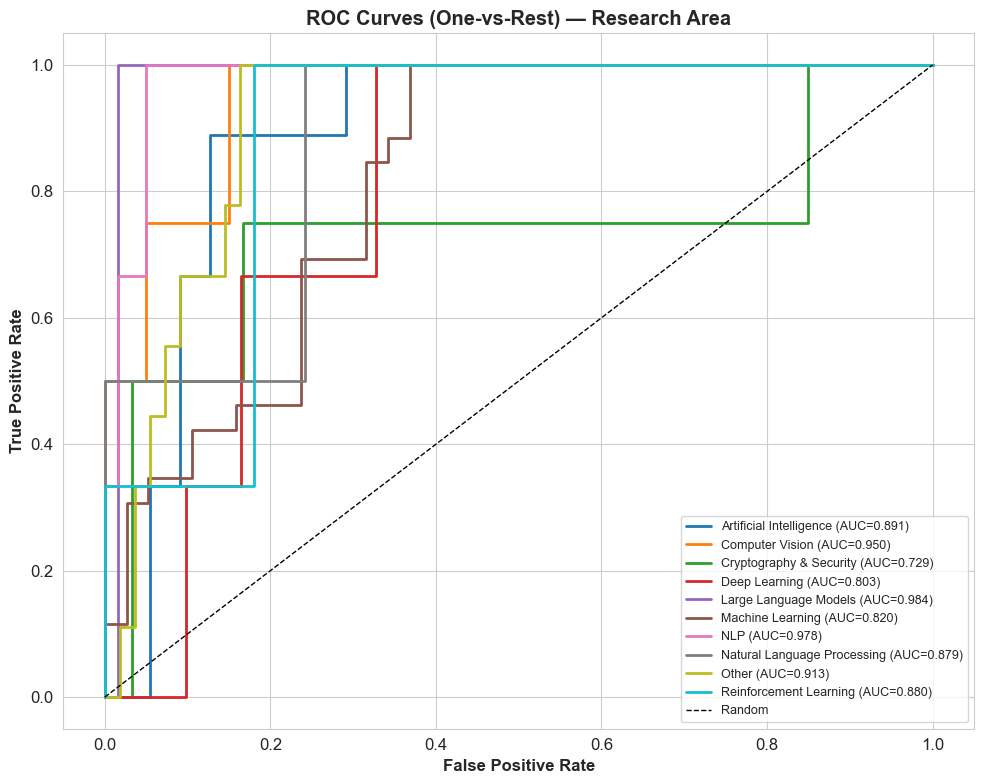

In [23]:
# Per-class ROC curves (One-vs-Rest)
from sklearn.preprocessing import label_binarize

ym_test_bin = label_binarize(ym_test, classes=range(len(class_names)))

fig, ax = plt.subplots(figsize=(10, 8))
colors = sns.color_palette('tab10', len(class_names))

for i, (cls_name, color) in enumerate(zip(class_names, colors)):
    fpr, tpr, _ = roc_curve(ym_test_bin[:, i], ym_pred_proba[:, i])
    roc_auc_val = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f'{cls_name} (AUC={roc_auc_val:.3f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random')
ax.set_xlabel('False Positive Rate', fontweight='bold')
ax.set_ylabel('True Positive Rate', fontweight='bold')
ax.set_title('ROC Curves (One-vs-Rest) — Research Area', fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

## 4. Regularization Analysis

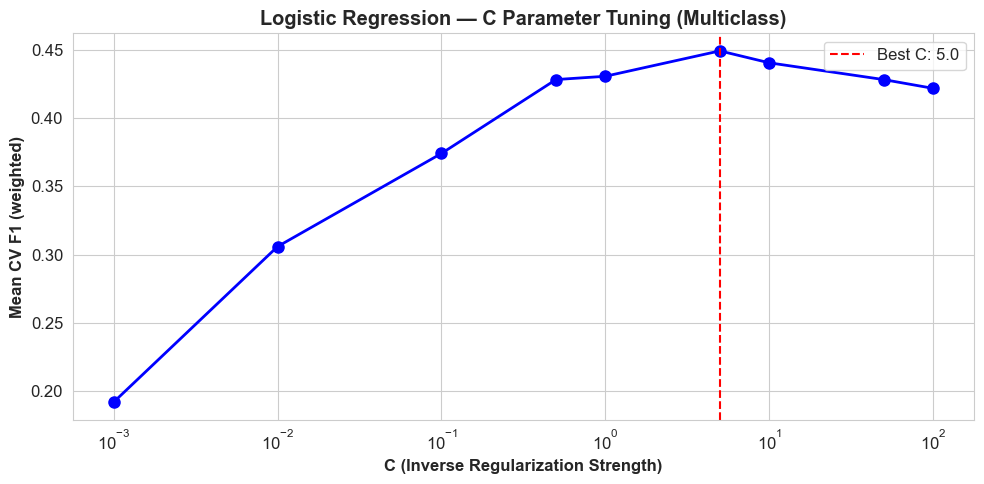

Best C: 5.0 (CV F1: 0.4493)


In [24]:
# C parameter tuning for multiclass
C_values = [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0]
cv_f1_scores = []

for c in C_values:
    pipe = Pipeline([
        ('preprocessor', preprocessor_mc),
        ('classifier', LogisticRegression(
            solver='lbfgs', max_iter=2000,
            random_state=42, class_weight='balanced', C=c
        ))
    ])
    scores = cross_val_score(pipe, X_mc, y_mc, cv=cv_mc, scoring='f1_weighted')
    cv_f1_scores.append(scores.mean())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(C_values, cv_f1_scores, 'bo-', linewidth=2, markersize=8)
ax.set_xscale('log')
ax.set_xlabel('C (Inverse Regularization Strength)', fontweight='bold')
ax.set_ylabel('Mean CV F1 (weighted)', fontweight='bold')
ax.set_title('Logistic Regression — C Parameter Tuning (Multiclass)', fontweight='bold')
best_c_idx = np.argmax(cv_f1_scores)
ax.axvline(C_values[best_c_idx], color='red', linestyle='--',
           label=f'Best C: {C_values[best_c_idx]}')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Best C: {C_values[best_c_idx]} (CV F1: {max(cv_f1_scores):.4f})')

In [25]:
# Retrain with best C
best_mc_pipeline = Pipeline([
    ('preprocessor', preprocessor_mc),
    ('classifier', LogisticRegression(
        solver='lbfgs', max_iter=2000,
        random_state=42, class_weight='balanced', C=C_values[best_c_idx]
    ))
])
best_mc_pipeline.fit(Xm_train, ym_train)
ym_pred_best = best_mc_pipeline.predict(Xm_test)

print(f'Best model accuracy: {accuracy_score(ym_test, ym_pred_best):.4f}')
print(f'Best model F1 (weighted): {f1_score(ym_test, ym_pred_best, average="weighted"):.4f}')
print(f'\nClassification Report (best model):\n')
print(classification_report(ym_test, ym_pred_best, target_names=class_names))

Best model accuracy: 0.5000
Best model F1 (weighted): 0.5112

Classification Report (best model):

                             precision    recall  f1-score   support

    Artificial Intelligence       0.33      0.22      0.27         9
            Computer Vision       0.67      0.50      0.57         4
    Cryptography & Security       0.50      0.50      0.50         4
              Deep Learning       0.18      0.67      0.29         3
      Large Language Models       0.00      0.00      0.00         1
           Machine Learning       0.67      0.54      0.60        26
                        NLP       0.67      0.67      0.67         3
Natural Language Processing       0.50      0.50      0.50         2
                      Other       0.60      0.67      0.63         9
     Reinforcement Learning       0.33      0.33      0.33         3

                   accuracy                           0.50        64
                  macro avg       0.44      0.46      0.44        64
  

## 5. Feature Importance

In [26]:
# Get feature names after preprocessing
ohe = best_mc_pipeline.named_steps['preprocessor'].transformers_[1][1]
cat_feature_names = ohe.get_feature_names_out(cat_features_mc).tolist()
all_feature_names = num_features_mc + cat_feature_names

coef_matrix = best_mc_pipeline.named_steps['classifier'].coef_
print(f'Coefficient matrix shape: {coef_matrix.shape}')
print(f'  ({coef_matrix.shape[0]} classes x {coef_matrix.shape[1]} features)')

# Top features per class
coef_df = pd.DataFrame(coef_matrix, columns=all_feature_names[:coef_matrix.shape[1]],
                       index=class_names)
coef_df.head()

Coefficient matrix shape: (10, 76)
  (10 classes x 76 features)


,rank_place,Number_of_Top_Venue_Papers,h_index,total_citations,NeurIPS,ICML,ICLR,AAAI,IJCAI,CVPR,...,University_University of Washington,University_University of Wisconsin-Madison,University_Vanderbilt University,University_Yale University,Rank_r1,Rank_r2,Venues_AAAI,Venues_AAAI;ACL,Venues_AAAI;CVPR,Venues_ACL
Artificial Intelligence,-0.200049,1.039503,-0.919824,0.350826,-0.783630,0.017164,0.242120,1.236319,0.0,-0.905420,...,-0.416369,-1.117154,-1.591918,-0.115013,0.105871,-0.063744,-0.223452,0.175408,0.000126,0.090046
Computer Vision,-0.004532,0.009120,-0.948417,0.432825,1.397398,0.022292,-0.618628,-0.642191,0.0,1.009027,...,-0.184036,-0.753724,-0.190452,-0.136049,0.035064,-0.039686,0.248916,-0.136191,-0.000647,-0.116700
Cryptography & Security,0.079963,0.871069,1.308352,-0.786486,-0.848885,-0.429946,-0.432510,-1.082882,0.0,-0.806032,...,0.854823,1.927663,-0.480203,-0.764578,0.004275,-0.040654,0.931051,-0.090865,0.000065,-0.876629
Deep Learning,0.206773,-0.159938,1.234281,0.532276,0.359752,0.593512,-0.575734,-0.799532,0.0,1.470484,...,-0.191732,2.065545,3.626729,-1.261421,0.186682,-0.141050,0.579848,-0.355213,-0.000941,-0.178062
Large Language Models,-1.046997,-0.472394,0.022466,0.919729,1.026932,-0.315221,-0.391367,0.032235,0.0,-0.398722,...,-0.035001,-0.222710,-0.053831,-0.095544,-0.043081,0.001121,0.026677,-0.021037,0.000219,-0.047819


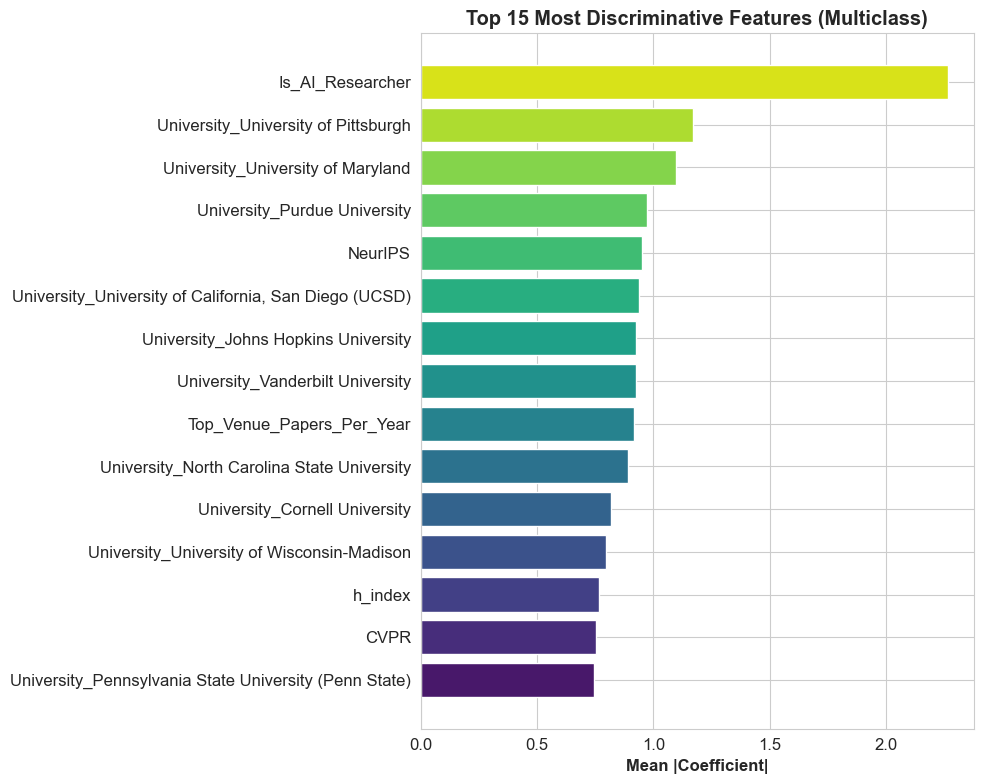

In [27]:
# Top 15 most discriminative features overall (highest mean absolute coef)
mean_abs_coef = coef_df.abs().mean(axis=0).sort_values(ascending=False)
top_features = mean_abs_coef.head(15)

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(top_features.index[::-1], top_features.values[::-1],
               color=sns.color_palette('viridis', 15))
ax.set_xlabel('Mean |Coefficient|', fontweight='bold')
ax.set_title('Top 15 Most Discriminative Features (Multiclass)', fontweight='bold')
plt.tight_layout()
plt.show()

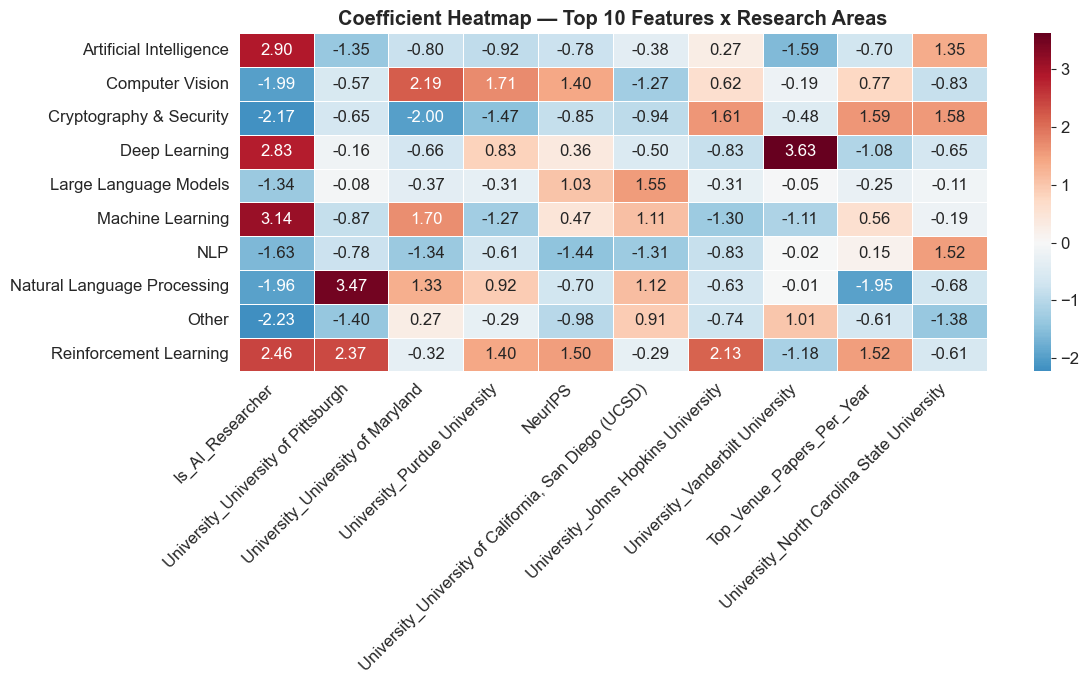

In [28]:
# Coefficient heatmap for top features
top10_features = mean_abs_coef.head(10).index.tolist()
coef_top = coef_df[top10_features]

fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(coef_top, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            linewidths=0.5, ax=ax)
ax.set_title('Coefficient Heatmap — Top 10 Features x Research Areas', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

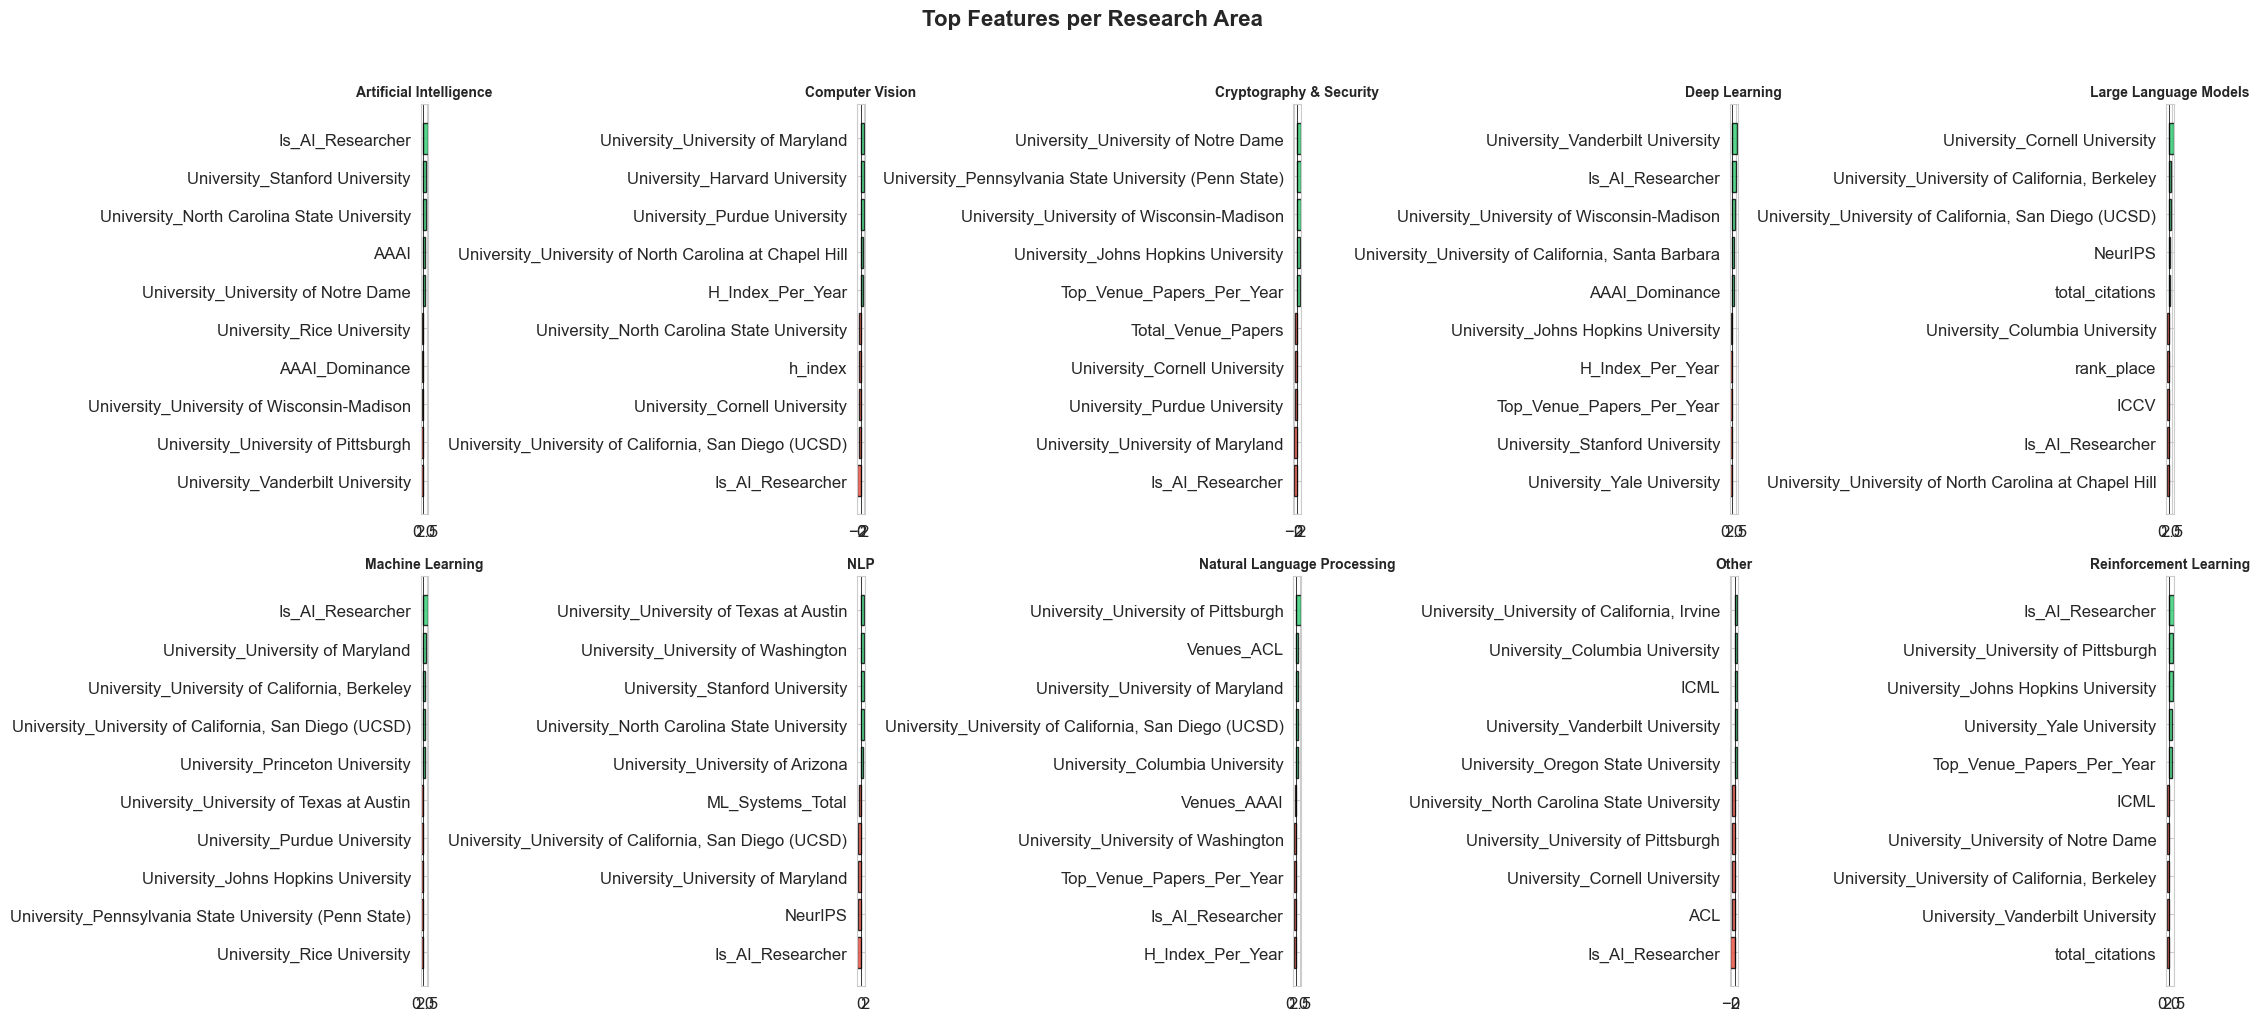

In [29]:
# Top features per class
fig, axes = plt.subplots(2, 5, figsize=(22, 10))

for i, (cls_name, ax) in enumerate(zip(class_names, axes.flat)):
    cls_coefs = coef_df.loc[cls_name].sort_values()
    top_pos = cls_coefs.tail(5)
    top_neg = cls_coefs.head(5)
    combined = pd.concat([top_neg, top_pos])
    
    colors = ['#e74c3c' if v < 0 else '#2ecc71' for v in combined.values]
    ax.barh(combined.index, combined.values, color=colors, edgecolor='black', alpha=0.8)
    ax.set_title(cls_name, fontweight='bold', fontsize=10)
    ax.axvline(x=0, color='black', linewidth=0.5)

plt.suptitle('Top Features per Research Area', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 6. Binary vs Multiclass Comparison

In [30]:
print('='*60)
print('  LOGISTIC REGRESSION -- FINAL SUMMARY')
print('='*60)
print()
print('  BINARY CLASSIFICATION (High Impact)')
print(f'  -----------------------------------')
print(f'  Target:       Is_High_Impact (citations >= {median_citations})')
print(f'  Accuracy:     {accuracy_score(yb_test, yb_pred):.4f}')
print(f'  F1 Score:     {f1_score(yb_test, yb_pred):.4f}')
print(f'  ROC AUC:      {roc_auc:.4f}')
print(f'  CV F1 (mean): {cv_scores.mean():.4f}')
print()
print('  MULTICLASS CLASSIFICATION (Research Area)')
print(f'  -----------------------------------------')
print(f'  Target:           Research area ({len(class_names)} classes)')
print(f'  Accuracy:         {accuracy_score(ym_test, ym_pred_best):.4f}')
print(f'  F1 (weighted):    {f1_score(ym_test, ym_pred_best, average="weighted"):.4f}')
print(f'  F1 (macro):       {f1_score(ym_test, ym_pred_best, average="macro"):.4f}')
print(f'  Best C:           {C_values[best_c_idx]}')
print(f'  CV F1 (mean):     {cv_scores_mc.mean():.4f}')
print('='*60)

  LOGISTIC REGRESSION -- FINAL SUMMARY

  BINARY CLASSIFICATION (High Impact)
  -----------------------------------
  Target:       Is_High_Impact (citations >= 4503.0)
  Accuracy:     0.9219
  F1 Score:     0.9180
  ROC AUC:      0.9824
  CV F1 (mean): 0.9167

  MULTICLASS CLASSIFICATION (Research Area)
  -----------------------------------------
  Target:           Research area (10 classes)
  Accuracy:         0.5000
  F1 (weighted):    0.5112
  F1 (macro):       0.4351
  Best C:           5.0
  CV F1 (mean):     0.4307
